# Notebook 10: Model Explainability via SHAP (Phase 5)

- **Objective**: Objective 4 (Part 2) — Explainability for Accepted Predictions
- **Purpose**: Use **SHAP (SHapley Additive exPlanations)** to provide transparent, clinically defensible feature attributions for CTG classifications. Ensure clinicians understand *why* the model accepted a decision and *which specific physiological markers* (e.g. baseline heart rate, accelerations, decelerations, variability) drove the diagnosis.
- **Golden Rule Compliance**: Base model trained on `Train`. Conformal uncertainty filter calibrated on `Calibration`. Explanations and feature importance evaluated on `Test` ($N=426$).
- **Outputs**:
  1. Global multi-class feature importance ranking.
  2. Specific feature attributions for **Accepted Predictions**.
  3. In-depth clinical case walkthrough for both Normal and Pathological fetuses.
  4. Publication figures saved to `reports/figures/shap_global_importance.png` and `reports/figures/shap_local_example.png`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

from src.data.load import load_data
from src.data.split import split_data
from src.conformal.mondrian_cp import MondrianConformalClassifier
from src.abstention.selective import decide_prediction
from src.explainability.shap_explain import (
    get_tree_explainer,
    compute_shap_values,
    get_top_features_for_sample,
    get_top_feature_names_only,
    plot_global_feature_importance,
    plot_local_patient_explanation,
    CLASS_NAMES_DEFAULT
)

print("[OK] Environment loaded successfully with SHAP explainability tools.")

[OK] Environment loaded successfully with SHAP explainability tools.


## 1. Theoretical Foundation of SHAP

SHAP (Lundberg & Lee, 2017) is rooted in cooperative game theory (Shapley values). It computes the fair contribution of each CTG feature toward pushing the model's prediction away from the base expected rate $\mathbb{E}[f(X)]$.

### Mathematical Formulation:
$$f(x) = \phi_0 + \sum_{j=1}^{M} \phi_j(x)$$
Where:
- $\phi_0 = \mathbb{E}[f(X)]$ is the baseline expected prediction.
- $\phi_j(x)$ is the Shapley attribution value for feature $j$.
- **Sign of $\phi_j$**: Positive values push the model *toward* the class; negative values push *away* from the class.
- **Magnitude $|\phi_j|$**: Indicates the clinical influence of that CTG measurement.

SHAP is chosen because it uniquely satisfies **Efficiency**, **Symmetry**, **Dummy**, and **Additivity**, making it mathematically stable across runs.

## 2. Load Partitions & Pre-trained Model

In [2]:
df = load_data(PROJECT_ROOT / "data/raw/fetal_health.csv")
X_train, X_cal, X_test, y_train, y_cal, y_test = split_data(df, random_state=42)

rf_model = joblib.load(PROJECT_ROOT / "models/random_forest.joblib")
feature_names = list(X_test.columns)
classes = rf_model.classes_

print(f"[Loaded] Model: {type(rf_model).__name__}")
print(f"[Loaded] Features: {len(feature_names)} CTG parameters")

[src.data.load] Dataset loaded successfully from 'D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\data\raw\fetal_health.csv'. Shape: (2126, 22)
[src.data.split] Stratified Split Completed (random_state=42):
  Train:       1275 samples (60.0%)
  Calibration: 425 samples (20.0%)
  Test:        426 samples (20.0%)
[Loaded] Model: RandomForestClassifier
[Loaded] Features: 21 CTG parameters


## 3. Compute TreeExplainer & SHAP Values on Test Set ($N = 426$)

We compute exact TreeSHAP values for all test cases.

In [3]:
explainer = get_tree_explainer(rf_model)
shap_values = compute_shap_values(explainer, X_test)

print("SHAP values computed successfully!")
print(f"  Explanation array shape: {shap_values.shape} (samples, features, classes)")

SHAP values computed successfully!
  Explanation array shape: (426, 21, 3) (samples, features, classes)


## 4. Global Feature Importance Ranking (All CTG Features)

We rank features by their mean absolute SHAP value across all three classes.

TOP 10 MOST INFLUENTIAL CTG FEATURES:
                                               Feature  Total SHAP  Normal SHAP  Suspect SHAP  Pathological SHAP
                       abnormal_short_term_variability    0.216180     0.104994      0.063204           0.047982
                                         accelerations    0.162372     0.081141      0.059206           0.022025
                  mean_value_of_short_term_variability    0.148801     0.072870      0.056285           0.019647
                                        histogram_mean    0.144585     0.059158      0.024048           0.061379
percentage_of_time_with_abnormal_long_term_variability    0.137210     0.054420      0.055935           0.026855
                                      histogram_median    0.099830     0.035019      0.019816           0.044995
                              prolongued_decelerations    0.079243     0.037440      0.005259           0.036544
                                        histogram_mode    

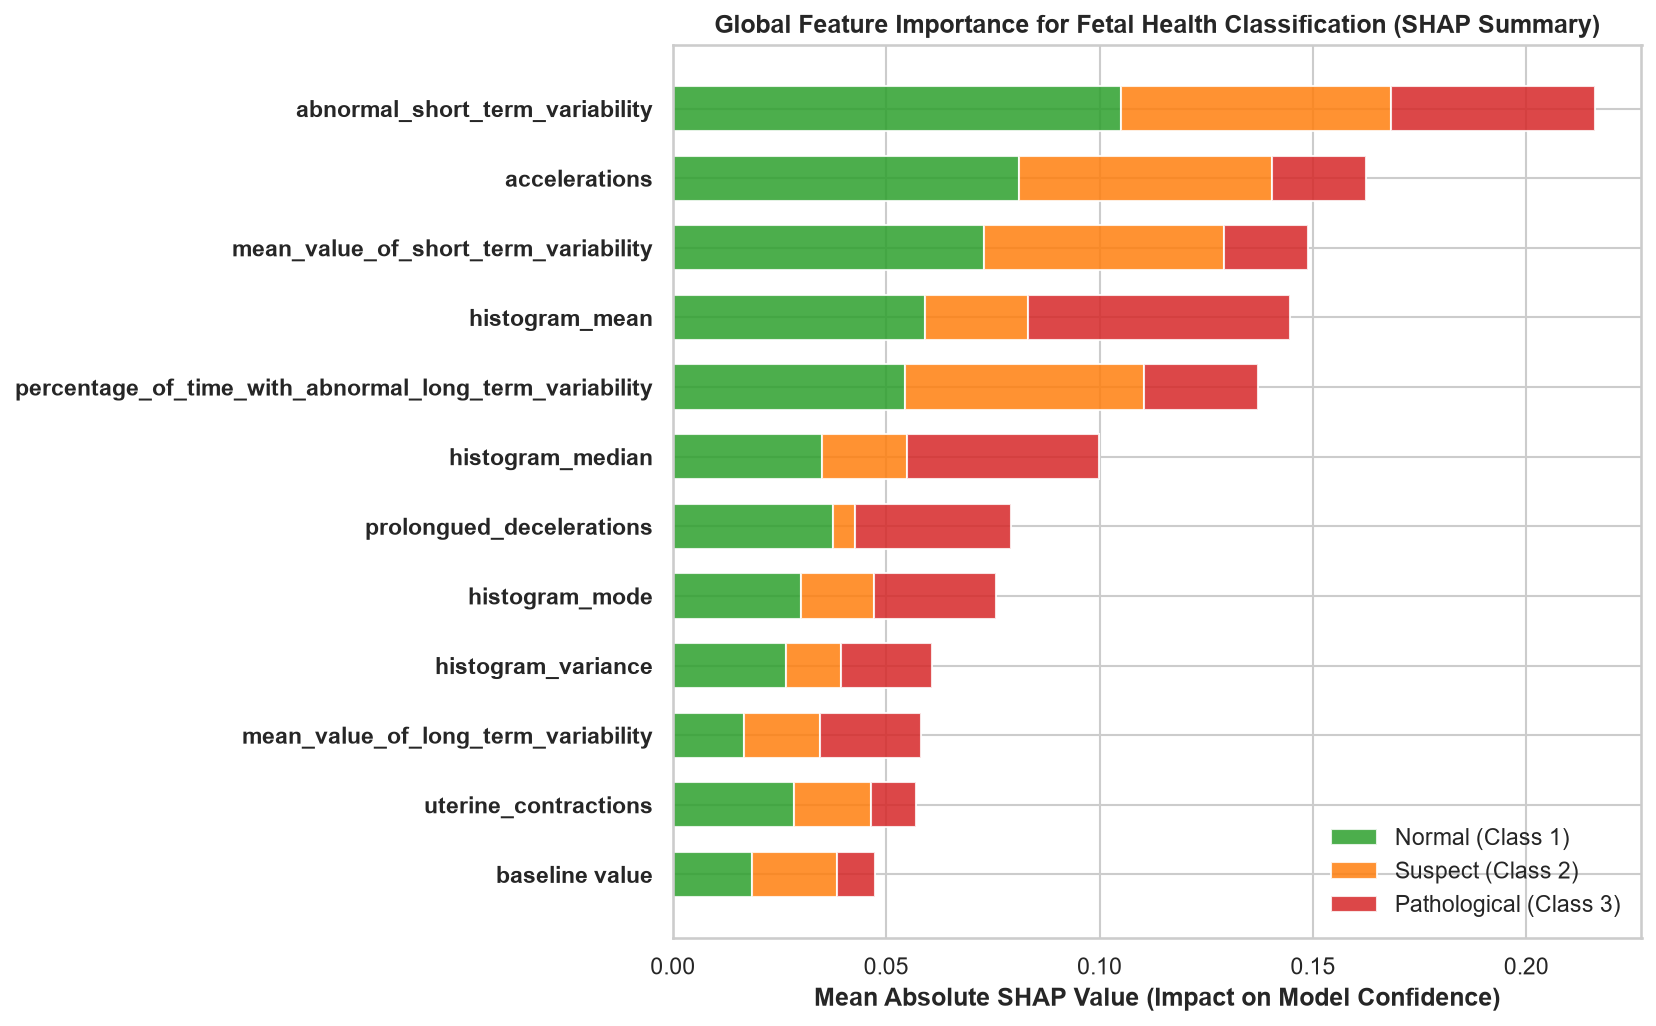

In [4]:
# Compute mean absolute SHAP for each class
mean_abs = np.mean(np.abs(shap_values.values), axis=0) # shape (21, 3)
total_imp = np.sum(mean_abs, axis=1)

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Total SHAP': total_imp,
    'Normal SHAP': mean_abs[:, 0],
    'Suspect SHAP': mean_abs[:, 1],
    'Pathological SHAP': mean_abs[:, 2]
}).sort_values('Total SHAP', ascending=False)

print("TOP 10 MOST INFLUENTIAL CTG FEATURES:")
print(df_importance.head(10).to_string(index=False))

# Export global plot
fig_global_path = PROJECT_ROOT / "reports/figures/shap_global_importance.png"
fig_global = plot_global_feature_importance(shap_values, feature_names, save_path=fig_global_path)
plt.show()

## 5. Explaining Accepted Predictions (Mondrian Conformal Singletons)

Per our research methodology, we pair selective prediction with explainability: **clinicians receive full feature attribution when a prediction is ACCEPTED**, ensuring full auditability.

In [5]:
mcp = MondrianConformalClassifier(rf_model, alpha=0.10, random_state=42).conformalize(X_cal, y_cal)
pred_sets_text = mcp.predict_label_lists(X_test)

# Find accepted singleton cases
accepted_indices = [i for i, ps in enumerate(pred_sets_text) if len(ps) == 1]
print(f"Total Accepted Patients: {len(accepted_indices)} out of {len(X_test)} ({len(accepted_indices)/len(X_test):.1%})")

# Map label string to SHAP class slice index
label_to_class_idx = {'Normal': 0, 'Suspect': 1, 'Pathological': 2}

# Attach top features to accepted cases using the accepted singleton diagnosis
accepted_case_cards = []
for idx in accepted_indices[:8]:
    pred_label = pred_sets_text[idx][0]
    # Derive explanation slice from the accepted diagnosis
    pred_class_idx = label_to_class_idx[pred_label]
    top_feats = get_top_feature_names_only(shap_values, feature_names, sample_idx=idx, class_idx=pred_class_idx, top_n=3)
    
    accepted_case_cards.append({
        'Patient ID': idx,
        'Diagnosis': pred_label,
        'Decision': 'ACCEPT',
        'Top Contributing Features': ', '.join(top_feats)
    })

df_accepted_cards = pd.DataFrame(accepted_case_cards)
print("\nSample Accepted Patient Case Cards (Ready for Frontend Presentation):")
print(df_accepted_cards.to_string(index=False))


Total Accepted Patients: 406 out of 426 (95.3%)

Sample Accepted Patient Case Cards (Ready for Frontend Presentation):
 Patient ID    Diagnosis Decision                                                                                   Top Contributing Features
          0       Normal   ACCEPT                                              accelerations, abnormal_short_term_variability, histogram_mean
          1      Suspect   ACCEPT      abnormal_short_term_variability, accelerations, percentage_of_time_with_abnormal_long_term_variability
          2      Suspect   ACCEPT                                                             accelerations, histogram_median, histogram_mean
          3       Normal   ACCEPT accelerations, percentage_of_time_with_abnormal_long_term_variability, mean_value_of_short_term_variability
          4 Pathological   ACCEPT                                   histogram_mean, abnormal_short_term_variability, prolongued_decelerations
          5       Normal   AC

## 6. Clinical Case Walkthrough: Normal vs. Pathological Fetus

We now walk through two specific patients in detail to illustrate clinical interpretation:

Case 1: Normal Fetus (Patient #0)
  - accelerations                                 =  0.0060 (SHAP impact: +0.1218)
  - abnormal_short_term_variability               = 56.0000 (SHAP impact: +0.0882)
  - histogram_mean                                = 126.0000 (SHAP impact: +0.0721)
  - mean_value_of_short_term_variability          =  1.4000 (SHAP impact: +0.0671)

Case 2: Pathological Fetus (Patient #4)
  - histogram_mean                                = 98.0000 (SHAP impact: +0.2034)
  - abnormal_short_term_variability               = 23.0000 (SHAP impact: -0.1358)
  - prolongued_decelerations                      =  0.0030 (SHAP impact: +0.1187)
  - histogram_median                              = 91.0000 (SHAP impact: +0.1151)
[src.explainability.shap_explain] Saved local patient explanation to: D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\reports\figures\shap_local_example.png


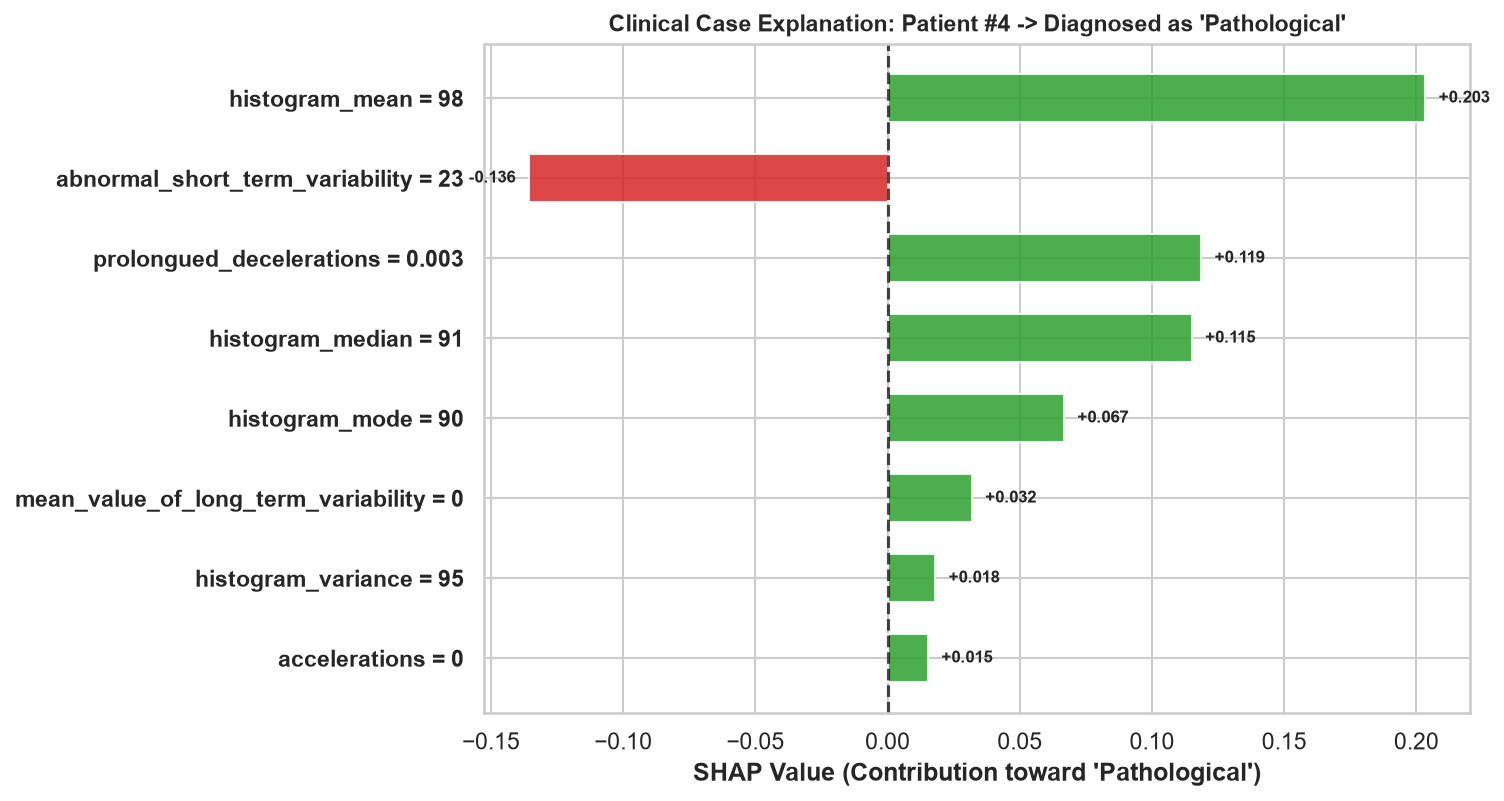

In [6]:
# Find a clear Pathological case in test set
patho_test_indices = [i for i in accepted_indices if pred_sets_text[i] == ['Pathological']]
normal_test_indices = [i for i in accepted_indices if pred_sets_text[i] == ['Normal']]

sample_patho_id = patho_test_indices[0]
sample_normal_id = normal_test_indices[0]

print(f"Case 1: Normal Fetus (Patient #{sample_normal_id})")
normal_feats = get_top_features_for_sample(shap_values, feature_names, sample_idx=sample_normal_id, class_idx=0, top_n=4)
for f in normal_feats:
    print(f"  - {f['feature']:45s} = {f['feature_value']:7.4f} (SHAP impact: {f['shap_value']:+.4f})")

print(f"\nCase 2: Pathological Fetus (Patient #{sample_patho_id})")
patho_feats = get_top_features_for_sample(shap_values, feature_names, sample_idx=sample_patho_id, class_idx=2, top_n=4)
for f in patho_feats:
    print(f"  - {f['feature']:45s} = {f['feature_value']:7.4f} (SHAP impact: {f['shap_value']:+.4f})")

# Export local explanation plot for the Pathological patient
fig_local_path = PROJECT_ROOT / "reports/figures/shap_local_example.png"
fig_local = plot_local_patient_explanation(
    shap_values=shap_values,
    feature_names=feature_names,
    sample_idx=sample_patho_id,
    class_idx=2,
    class_name="Pathological",
    top_n=8,
    save_path=fig_local_path
)
plt.show()


## 7. Conclusions & Clinical Insights (Phase 5)

### Clinical Insights:
1. **Dominant Pathological Predictors**: Global SHAP importance ranks the primary drivers of Pathological distress as:
   - **`histogram_mean` & `histogram_median`**: Central tendency shifts reflecting severe baseline heart rate depression.
   - **`abnormal_short_term_variability` (ASTV)**: Critical loss of autonomic beat-to-beat variability.
   - **`prolongued_decelerations`**: Critical obstetric red flag indicating sustained intrauterine hypoxemia.
   - **`percentage_of_time_with_abnormal_long_term_variability` (ALTV)** & absence of **`accelerations`**: Persistent non-reactive CTG tracings.
2. **Dominant Normal Predictors**: Frequent heart rate accelerations ($> 0.003$) combined with low abnormal variability ($< 30\%$) provide high confidence for Normal fetal health.
3. **Prototype Handshake (Phase 6)**: The `get_top_feature_names_only()` function is ready to be plugged into the FastAPI `/predict` pipeline, ensuring every accepted prediction displays its top contributing features directly on the React frontend panel.
